# Removing Outliers: Outlier Trimming

An **outlier** is an observation that deviates substantially from the overall pattern of the data. 

**Outlier trimming** (or truncation) consists of identifying data points that fall outside reasonable statistical boundaries and removing those rows entirely from the dataset.

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand the three classical statistical criteria for identifying outliers:
   - **Interquartile Range (IQR) / Tukey's Fences** (best for skewed data).
   - **Gaussian / Standard Deviation Rule** (best for normally distributed data).
   - **Quantile / Percentile Thresholds** (empirical cutoffs).
2. Follow critical machine learning best practices:
   - Compute outlier thresholds **strictly on the training set** to prevent data leakage.
   - Synchronize predictor features ($X$) and target variables ($y$) when trimming rows.
   - Understand why **trimming test data is generally inappropriate** in real-world ML pipelines.
3. Diagnose and visualize distributions before and after outlier removal using boxplots and histograms.

---
## 1. Outlier Detection Methods & When to Use Them

| Method | Distribution Assumption | Upper Limit | Lower Limit | Typical Multiplier |
| :--- | :--- | :--- | :--- | :--- |
| **IQR (Tukey's Fences)** | Skewed or non-normal | $Q_3 + (k \cdot IQR)$ | $Q_1 - (k \cdot IQR)$ | $k = 1.5$ (outliers), $k = 3.0$ (extreme outliers) |
| **Gaussian (Mean $\pm$ Std)** | Normal (bell curve) | $\mu + (k \cdot \sigma)$ | $\mu - (k \cdot \sigma)$ | $k = 2$ ($95.4\%$ coverage) or $k = 3$ ($99.7\%$ coverage) |
| **Quantiles / Percentiles** | Any distribution | High percentile (e.g., $99^{\text{th}}$) | Low percentile (e.g., $1^{\text{st}}$) | Fixed percentile cutoffs |

---

### ⚠️ Critical Machine Learning Reality: Trimming in ML Pipelines
1. **Synchronizing $X$ and $y$**: In supervised learning, every row in $X$ corresponds to a label in $y$. If you remove rows from $X_{train}$, you **must** filter $y_{train}$ with the exact same boolean mask, or model training (`model.fit(X, y)`) will fail due to mismatched dimensions.
2. **What about the Test Set?** In production evaluation, you **cannot simply drop test observations** just because they are unusual! A production model must make predictions for any incoming data. Therefore, outlier trimming is primarily used to clean the **training set** so outliers do not distort model weights. If handling test outliers is necessary, **Capping / Winsorization** (Notebook 02) is preferred.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

# Matplotlib styling
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading the Dataset & Splitting Train/Test

We use the California Housing dataset from scikit-learn. To prevent data leakage, we split our data into training and test sets **before** calculating any statistical bounds.

In [2]:
# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)
data = housing.frame

print(f"Dataset shape: {data.shape}")
data.head()

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Separate predictors and target
X = data.drop("MedHouseVal", axis=1)
y = data["MedHouseVal"]

# Train/Test Split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")

X_train: (14448, 8), y_train: (14448,)
X_test:  (6192, 8),  y_test:  (6192,)


---
## 3. Diagnostic Visualization Helper

To inspect feature distributions and identify outliers, we plot a **histogram** (showing the shape and density) and a **boxplot** (highlighting points beyond the fences) side-by-side.

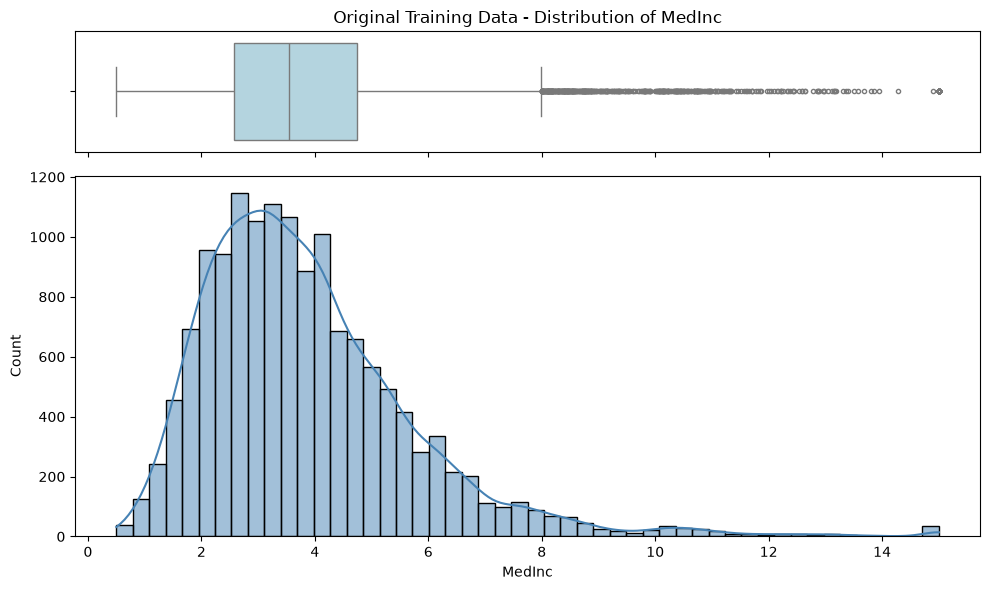

In [4]:
def plot_distribution(df, variable, title=""):
    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [0.25, 0.75]}
    )
    
    # Modern horizontal boxplot without deprecated parameters
    sns.boxplot(x=df[variable], ax=ax_box, color='lightblue', fliersize=3)
    ax_box.set(xlabel='')
    ax_box.set_title(f"{title} - Distribution of {variable}" if title else f"Distribution of {variable}")
    
    # Histogram + KDE
    sns.histplot(df[variable], ax=ax_hist, kde=True, color='steelblue', bins=50)
    ax_hist.set_ylabel("Count")
    
    plt.tight_layout()
    plt.show()

# Inspect 'MedInc' (Median Income) before trimming
plot_distribution(X_train, "MedInc", title="Original Training Data")

Notice how `MedInc` is right-skewed, with individual points stretching past $10$ and up to $15$. These points clearly stand out on the boxplot.

---
## 4. Method 1: The IQR Rule (Tukey's Fences)

Because `MedInc` is skewed, the **IQR method** is the most statistically sound approach.

$$\text{IQR} = Q_3 - Q_1$$
$$\text{Lower Limit} = Q_1 - (k \cdot \text{IQR})$$
$$\text{Upper Limit} = Q_3 + (k \cdot \text{IQR})$$

We use $k = 3.0$ to target **extreme outliers** while preserving genuine variations.

In [5]:
def find_iqr_limits(df, variable, fold=1.5):
    q25 = df[variable].quantile(0.25)
    q75 = df[variable].quantile(0.75)
    iqr = q75 - q25
    
    lower_limit = q25 - (iqr * fold)
    upper_limit = q75 + (iqr * fold)
    
    return lower_limit, upper_limit

# Calculate limits on X_train ONLY
lower_iqr, upper_iqr = find_iqr_limits(X_train, "MedInc", fold=3.0)
print(f"IQR Extreme Limits for MedInc (fold=3.0):")
print(f"  Lower Limit: {lower_iqr:.3f}")
print(f"  Upper Limit: {upper_iqr:.3f}")

IQR Extreme Limits for MedInc (fold=3.0):
  Lower Limit: -3.926
  Upper Limit: 11.233


### Synchronized Trimming on Training Data

In [6]:
# Create boolean mask for inliers using .between()
inliers_train_iqr = X_train["MedInc"].between(lower_iqr, upper_iqr)

# Synchronously trim BOTH X_train and y_train
X_train_iqr = X_train.loc[inliers_train_iqr].copy()
y_train_iqr = y_train.loc[inliers_train_iqr].copy()

# Calculate removed rows
num_removed = len(X_train) - len(X_train_iqr)
pct_removed = (num_removed / len(X_train)) * 100

print(f"Original X_train rows: {len(X_train)}")
print(f"Trimmed X_train rows:  {len(X_train_iqr)} (Removed: {num_removed} rows, {pct_removed:.2f}%)")
print(f"Verify y_train shape matches X_train: {len(y_train_iqr) == len(X_train_iqr)}")

Original X_train rows: 14448
Trimmed X_train rows:  14348 (Removed: 100 rows, 0.69%)
Verify y_train shape matches X_train: True


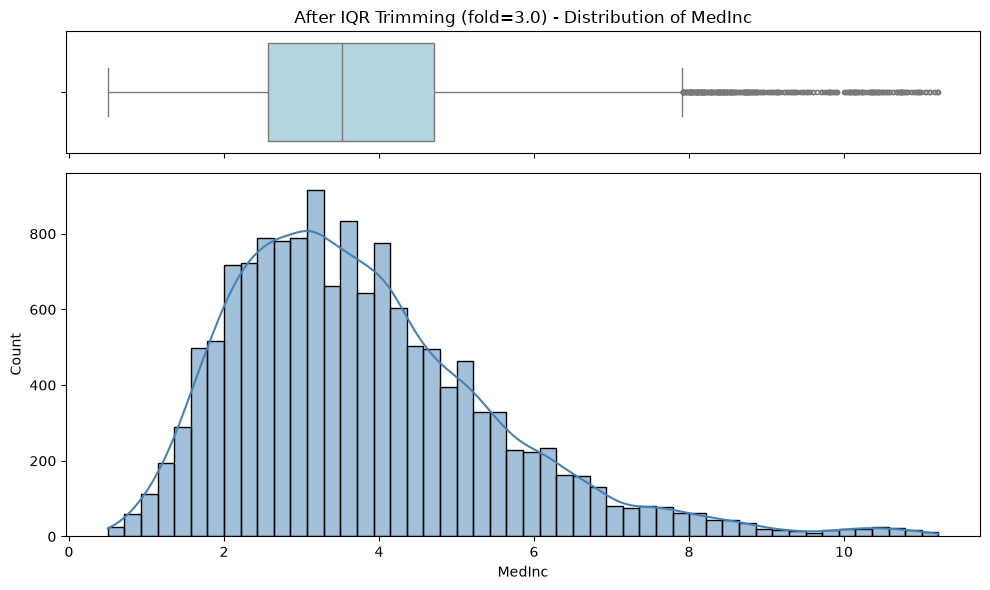

In [7]:
# Visualize distribution after IQR trimming
plot_distribution(X_train_iqr, "MedInc", title="After IQR Trimming (fold=3.0)")

---
## 5. Method 2: The Gaussian / Standard Deviation Rule

For variables that follow a bell-shaped (normal) distribution, the **Empirical Rule** states that:
- $\approx 68.3\%$ of observations lie within $\mu \pm 1\sigma$
- $\approx 95.4\%$ of observations lie within $\mu \pm 2\sigma$
- $\approx 99.7\%$ of observations lie within $\mu \pm 3\sigma$

Observations beyond $\mu \pm 3\sigma$ are rare statistical anomalies under normality.

In [8]:
def find_gaussian_limits(df, variable, fold=3.0):
    mean = df[variable].mean()
    std = df[variable].std()
    
    lower_limit = mean - (std * fold)
    upper_limit = mean + (std * fold)
    
    return lower_limit, upper_limit

# Compute limits on X_train only
lower_gauss, upper_gauss = find_gaussian_limits(X_train, "MedInc", fold=3.0)
print(f"Gaussian Limits for MedInc (fold=3.0):")
print(f"  Lower Limit: {lower_gauss:.3f}")
print(f"  Upper Limit: {upper_gauss:.3f}")

Gaussian Limits for MedInc (fold=3.0):
  Lower Limit: -1.807
  Upper Limit: 9.540


In [9]:
# Synchronously filter training data
inliers_train_gauss = X_train["MedInc"].between(lower_gauss, upper_gauss)

X_train_gauss = X_train.loc[inliers_train_gauss].copy()
y_train_gauss = y_train.loc[inliers_train_gauss].copy()

print(f"Trimmed X_train rows: {len(X_train_gauss)} (Removed: {len(X_train) - len(X_train_gauss)})")
print(f"Synchronized with y_train: {len(X_train_gauss) == len(y_train_gauss)}")

Trimmed X_train rows: 14211 (Removed: 237)
Synchronized with y_train: True


---
## 6. Method 3: Quantile / Percentile Trimming

When distributions are arbitrary or empirical cutoffs are mandated by domain rules, we can trim at fixed percentiles (e.g., $1^{\text{st}}$ and $99^{\text{th}}$ percentiles).

In [10]:
# Compute percentiles strictly on X_train
lower_q = X_train["MedInc"].quantile(0.01)
upper_q = X_train["MedInc"].quantile(0.99)

print(f"Quantile Boundaries (1st and 99th):")
print(f"  Lower (1%):  {lower_q:.3f}")
print(f"  Upper (99%): {upper_q:.3f}")

# Synchronously filter
inliers_train_q = X_train["MedInc"].between(lower_q, upper_q)

X_train_q = X_train.loc[inliers_train_q].copy()
y_train_q = y_train.loc[inliers_train_q].copy()

print(f"Trimmed rows: {len(X_train_q)} (Removed exactly 2% = {len(X_train) - len(X_train_q)} rows)")

Quantile Boundaries (1st and 99th):
  Lower (1%):  1.055
  Upper (99%): 10.631
Trimmed rows: 14158 (Removed exactly 2% = 290 rows)


---
## 7. Summary & Best Practices Checklist

| Rule | When to Use | Key Strength | Potential Weakness |
| :--- | :--- | :--- | :--- |
| **IQR (Tukey)** | Skewed data or unknown distributions | Non-parametric; unaffected by extreme values | Can remove valid tail events if multiplier $k$ is too low |
| **Gaussian ($\mu \pm 3\sigma$)** | Normally distributed features | Grounded in statistical probability theory | Sensitive to extreme outliers because $\mu$ and $\sigma$ are pulled by the outliers themselves |
| **Quantiles (e.g. 1% / 99%)** | Domain-mandated empirical cutoffs | Guarantees exact percentage of records removed | Arbitrary cutoff that always drops data even if no genuine outliers exist |

### Core ML Rules:
1. **Never calculate limits on the full dataset**: Compute quantiles, mean, and std strictly on `X_train`.
2. **Synchronize Targets**: Always filter `y_train` whenever `X_train` rows are dropped.
3. **Avoid Trimming Test Sets**: For unseen test or production data, keep all rows intact or apply **capping** (see Notebook 02).
